# PyTorch 入门：用神经网络预测电声耦合强度 λ

这个 notebook 模拟你的超导研究场景：
- **输入**：50个频率 bin 的 a2F 声子谱
- **输出**：电声耦合强度 λ（回归问题）

我们会对比：**线性回归 vs 两层神经网络 vs 三层神经网络**

---

## 0. 安装依赖（如果没有的话）

In [1]:
# 如果没有安装，取消注释运行
# !pip install torch numpy matplotlib scikit-learn

## 1. 导入库

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score

# 固定随机种子，保证结果可复现
torch.manual_seed(42)
np.random.seed(42)

print(f"PyTorch 版本: {torch.__version__}")
print(f"使用设备: {'GPU (CUDA)' if torch.cuda.is_available() else 'CPU (M系列Mac用MPS)'}")

# 自动选择设备
if torch.cuda.is_available():
    device = torch.device('cuda')
elif torch.backends.mps.is_available():  # M5 Pro Mac
    device = torch.device('mps')
else:
    device = torch.device('cpu')
print(f"实际使用: {device}")

PyTorch 版本: 2.11.0
使用设备: CPU (M系列Mac用MPS)
实际使用: mps


## 2. 生成合成数据

模拟真实物理：
- 每个样本是一个 50-bin 的 a2F(ω) 谱
- λ 由 Eliashberg 积分决定：$\lambda = 2\sum_i \frac{a2F_i}{\omega_i} \Delta\omega$
- 加入适量噪声模拟计算误差

In [3]:
def generate_a2F_spectra(n_samples=500, n_bins=50):
    """
    生成合成 a2F 谱和对应的 λ
    
    物理假设：
    - 频率范围 0.01 ~ 0.1 Ry (典型声子频率)
    - a2F 谱形状：1~3个高斯峰的叠加
    - λ 由 1/ω 加权积分计算
    """
    omegas = np.linspace(0.005, 0.12, n_bins)  # 频率轴
    d_omega = omegas[1] - omegas[0]
    
    spectra = np.zeros((n_samples, n_bins))
    lambdas = np.zeros(n_samples)
    
    for i in range(n_samples):
        # 随机生成1-3个声子峰
        n_peaks = np.random.randint(1, 4)
        spectrum = np.zeros(n_bins)
        
        for _ in range(n_peaks):
            center = np.random.uniform(0.01, 0.10)  # 峰中心
            width  = np.random.uniform(0.005, 0.02) # 峰宽
            height = np.random.uniform(0.1, 2.0)    # 峰高（耦合强度）
            spectrum += height * np.exp(-0.5 * ((omegas - center) / width) ** 2)
        
        spectra[i] = spectrum
        
        # 计算真实 λ（Eliashberg 积分）
        lambda_true = 2 * np.sum(spectrum / omegas) * d_omega
        # 加入 5% 噪声
        lambdas[i] = lambda_true * (1 + 0.05 * np.random.randn())
    
    return spectra, lambdas, omegas

# 生成数据
X, y, omegas = generate_a2F_spectra(n_samples=500, n_bins=50)
print(f"数据形状: X={X.shape}, y={y.shape}")
print(f"λ 范围: {y.min():.3f} ~ {y.max():.3f}")
print(f"λ 均值: {y.mean():.3f} ± {y.std():.3f}")

数据形状: X=(500, 50), y=(500,)
λ 范围: 0.048 ~ 14.345
λ 均值: 3.405 ± 2.608


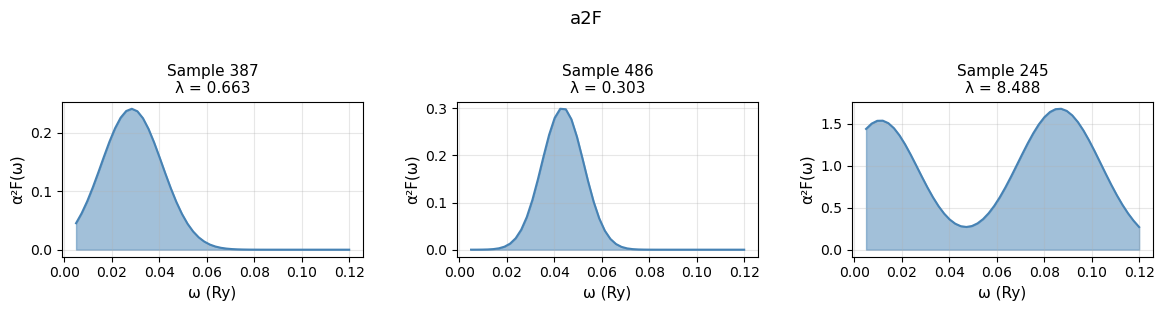

In [4]:
# 可视化几个样本谱
fig, axes = plt.subplots(1, 3, figsize=(12, 3))

for i, ax in enumerate(axes):
    idx = np.random.randint(0, len(X))
    ax.fill_between(omegas, X[idx], alpha=0.5, color='steelblue')
    ax.plot(omegas, X[idx], color='steelblue')
    ax.set_xlabel('ω (Ry)', fontsize=11)
    ax.set_ylabel('α²F(ω)', fontsize=11)
    ax.set_title(f'Sample {idx}\nλ = {y[idx]:.3f}', fontsize=11)
    ax.grid(alpha=0.3)

plt.suptitle('a2F', fontsize=13, y=1.02)
plt.tight_layout()
plt.show()

## 3. 数据预处理

神经网络对输入尺度敏感，必须做标准化。

In [5]:
# Train/Test 分割
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 标准化特征（用训练集的均值和方差）
scaler_X = StandardScaler()
X_train_scaled = scaler_X.fit_transform(X_train)
X_test_scaled  = scaler_X.transform(X_test)  # 注意：只用 transform，不 fit

# 标准化目标值
scaler_y = StandardScaler()
y_train_scaled = scaler_y.fit_transform(y_train.reshape(-1, 1)).ravel()
y_test_scaled  = scaler_y.transform(y_test.reshape(-1, 1)).ravel()

# 转换为 PyTorch Tensor
X_train_t = torch.FloatTensor(X_train_scaled).to(device)
X_test_t  = torch.FloatTensor(X_test_scaled).to(device)
y_train_t = torch.FloatTensor(y_train_scaled).to(device)
y_test_t  = torch.FloatTensor(y_test_scaled).to(device)

# 创建 DataLoader（自动分批）
train_dataset = TensorDataset(X_train_t, y_train_t)
train_loader  = DataLoader(train_dataset, batch_size=32, shuffle=True)

print(f"训练集: {X_train_t.shape}, 测试集: {X_test_t.shape}")
print(f"每个 batch: {next(iter(train_loader))[0].shape}")

训练集: torch.Size([400, 50]), 测试集: torch.Size([100, 50])
每个 batch: torch.Size([32, 50])


## 4. 定义模型

三种模型做对比：
- **线性回归**：没有隐藏层（基准）
- **浅层网络**：1个隐藏层
- **深层网络**：3个隐藏层 + Dropout 正则化

In [6]:
class LinearRegression(nn.Module):
    """基准：线性模型（等价于普通线性回归）"""
    def __init__(self, input_dim):
        super().__init__()
        self.linear = nn.Linear(input_dim, 1)
    
    def forward(self, x):
        return self.linear(x).squeeze()


class ShallowNet(nn.Module):
    """浅层网络：输入 → 64 → 输出"""
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 1)
        )
    
    def forward(self, x):
        return self.net(x).squeeze()


class DeepNet(nn.Module):
    """深层网络：输入 → 128 → 64 → 32 → 输出，含 Dropout"""
    def __init__(self, input_dim, dropout=0.2):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.ReLU(),
            nn.Dropout(dropout),      # 随机丢弃20%神经元，防过拟合
            
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(dropout),
            
            nn.Linear(64, 32),
            nn.ReLU(),
            
            nn.Linear(32, 1)
        )
    
    def forward(self, x):
        return self.net(x).squeeze()


# 统计参数量
def count_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

input_dim = X_train_t.shape[1]  # 50 bins
print(f"输入维度: {input_dim}")
print(f"LinearRegression 参数量: {count_params(LinearRegression(input_dim)):,}")
print(f"ShallowNet      参数量: {count_params(ShallowNet(input_dim)):,}")
print(f"DeepNet         参数量: {count_params(DeepNet(input_dim)):,}")

输入维度: 50
LinearRegression 参数量: 51
ShallowNet      参数量: 3,329
DeepNet         参数量: 16,897


## 5. 训练函数

PyTorch 训练的标准循环：**前向传播 → 计算 loss → 反向传播 → 更新参数**

In [7]:
def train_model(model, train_loader, X_test, y_test, 
                n_epochs=200, lr=1e-3, verbose=True):
    """
    标准 PyTorch 训练循环
    返回：训练损失历史、测试损失历史
    """
    model = model.to(device)
    optimizer = optim.Adam(model.parameters(), lr=lr)  # Adam 优化器
    criterion = nn.MSELoss()                            # 均方误差损失
    
    # 学习率调度器：如果 loss 10个 epoch 没改善，lr 降低一半
    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, patience=10, factor=0.5
    )
    
    train_losses = []
    test_losses  = []
    
    for epoch in range(n_epochs):
        # ---- 训练阶段 ----
        model.train()  # 开启 Dropout 等训练模式
        epoch_loss = 0
        
        for X_batch, y_batch in train_loader:
            optimizer.zero_grad()          # 梯度清零
            y_pred = model(X_batch)        # 前向传播
            loss = criterion(y_pred, y_batch)  # 计算损失
            loss.backward()                # 反向传播（自动微分）
            optimizer.step()               # 更新参数
            epoch_loss += loss.item()
        
        avg_train_loss = epoch_loss / len(train_loader)
        
        # ---- 评估阶段 ----
        model.eval()  # 关闭 Dropout
        with torch.no_grad():  # 不计算梯度（节省内存）
            y_test_pred = model(X_test)
            test_loss = criterion(y_test_pred, y_test).item()
        
        scheduler.step(test_loss)
        train_losses.append(avg_train_loss)
        test_losses.append(test_loss)
        
        if verbose and (epoch + 1) % 50 == 0:
            print(f"Epoch {epoch+1:3d}/{n_epochs} | "
                  f"Train Loss: {avg_train_loss:.4f} | "
                  f"Test Loss: {test_loss:.4f}")
    
    return train_losses, test_losses


def evaluate_model(model, X_test, y_test_scaled, scaler_y):
    """计算 R² 分数（反标准化后）"""
    model.eval()
    with torch.no_grad():
        y_pred_scaled = model(X_test).cpu().numpy()
    
    # 反标准化
    y_pred = scaler_y.inverse_transform(y_pred_scaled.reshape(-1, 1)).ravel()
    y_true = scaler_y.inverse_transform(y_test_scaled.cpu().numpy().reshape(-1, 1)).ravel()
    
    r2 = r2_score(y_true, y_pred)
    return r2, y_true, y_pred

## 6. 训练三个模型

In [8]:
N_EPOCHS = 300
results = {}

models = {
    'Linear Regression': LinearRegression(input_dim),
    'Shallow Net (1 layer)': ShallowNet(input_dim),
    'Deep Net (3 layers)': DeepNet(input_dim),
}

for name, model in models.items():
    print(f"\n{'='*50}")
    print(f"训练: {name}")
    print('='*50)
    
    train_losses, test_losses = train_model(
        model, train_loader, X_test_t, y_test_t,
        n_epochs=N_EPOCHS, lr=1e-3
    )
    
    r2, y_true, y_pred = evaluate_model(model, X_test_t, y_test_t, scaler_y)
    print(f"\n最终 Test R²: {r2:.4f}")
    
    results[name] = {
        'model': model,
        'train_losses': train_losses,
        'test_losses': test_losses,
        'r2': r2,
        'y_true': y_true,
        'y_pred': y_pred
    }


训练: Linear Regression
Epoch  50/300 | Train Loss: 0.0081 | Test Loss: 0.0066
Epoch 100/300 | Train Loss: 0.0065 | Test Loss: 0.0062
Epoch 150/300 | Train Loss: 0.0067 | Test Loss: 0.0061
Epoch 200/300 | Train Loss: 0.0066 | Test Loss: 0.0061
Epoch 250/300 | Train Loss: 0.0063 | Test Loss: 0.0061
Epoch 300/300 | Train Loss: 0.0065 | Test Loss: 0.0061

最终 Test R²: 0.9915

训练: Shallow Net (1 layer)
Epoch  50/300 | Train Loss: 0.0049 | Test Loss: 0.0076
Epoch 100/300 | Train Loss: 0.0038 | Test Loss: 0.0073
Epoch 150/300 | Train Loss: 0.0038 | Test Loss: 0.0073
Epoch 200/300 | Train Loss: 0.0038 | Test Loss: 0.0073
Epoch 250/300 | Train Loss: 0.0038 | Test Loss: 0.0073
Epoch 300/300 | Train Loss: 0.0040 | Test Loss: 0.0073

最终 Test R²: 0.9899

训练: Deep Net (3 layers)
Epoch  50/300 | Train Loss: 0.0168 | Test Loss: 0.0068
Epoch 100/300 | Train Loss: 0.0160 | Test Loss: 0.0095
Epoch 150/300 | Train Loss: 0.0177 | Test Loss: 0.0090
Epoch 200/300 | Train Loss: 0.0146 | Test Loss: 0.0090
Epoch

## 7. 可视化结果

/var/folders/4c/5k7p_1052bxdltqypq0b9dw00000gn/T/ipykernel_18254/1769081781.py:39: UserWarning: Glyph 26354 (\N{CJK UNIFIED IDEOGRAPH-66F2}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/var/folders/4c/5k7p_1052bxdltqypq0b9dw00000gn/T/ipykernel_18254/1769081781.py:39: UserWarning: Glyph 32447 (\N{CJK UNIFIED IDEOGRAPH-7EBF}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/opt/homebrew/Caskroom/miniconda/base/envs/matsci/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 26354 (\N{CJK UNIFIED IDEOGRAPH-66F2}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/opt/homebrew/Caskroom/miniconda/base/envs/matsci/lib/python3.11/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 32447 (\N{CJK UNIFIED IDEOGRAPH-7EBF}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


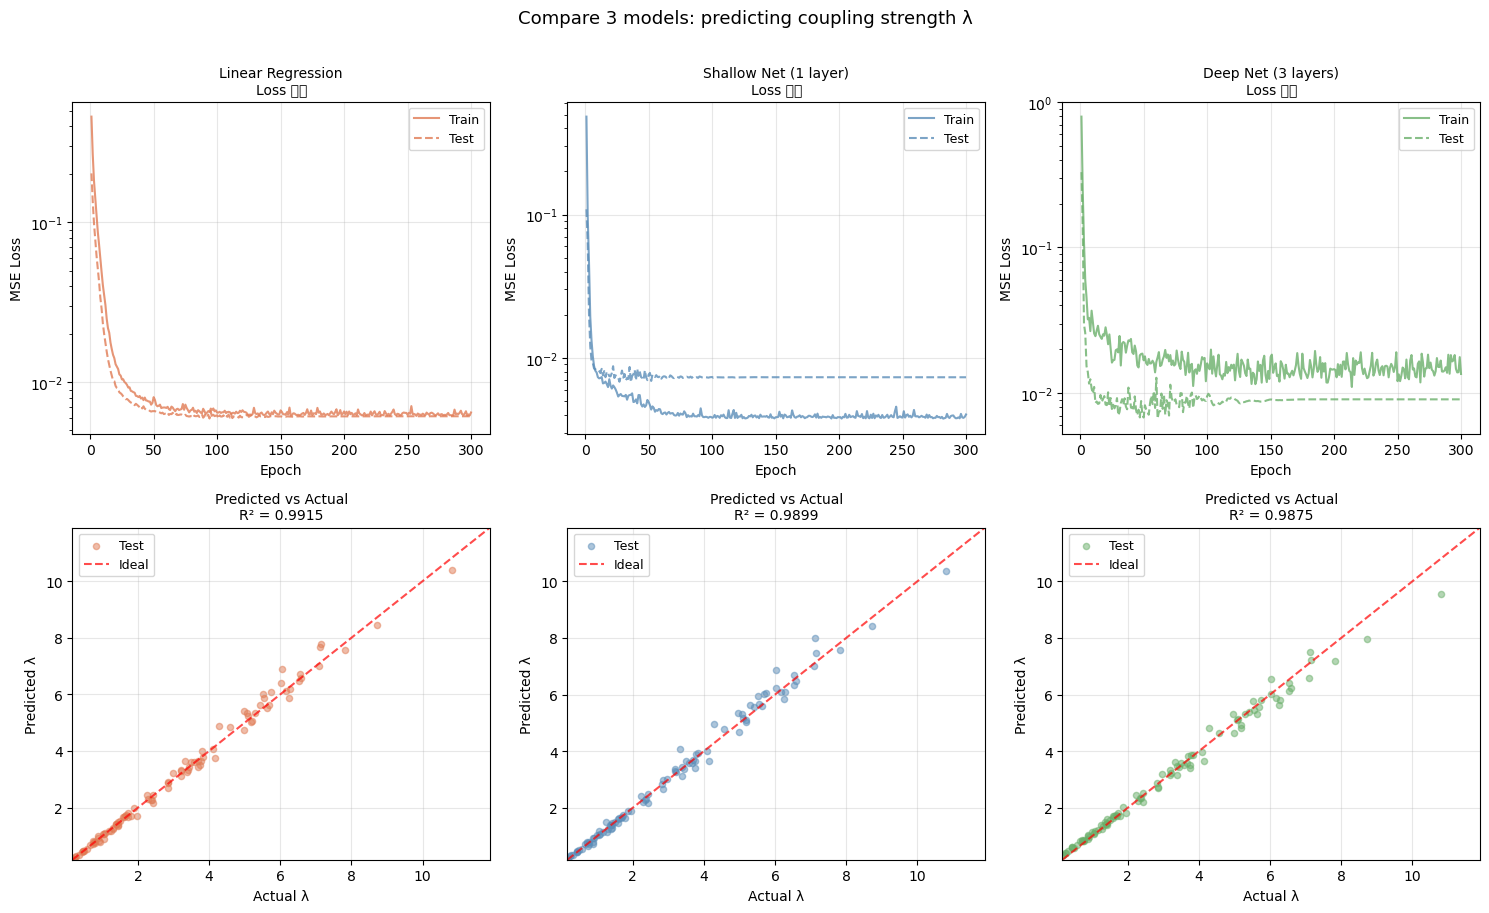


模型性能汇总:
----------------------------------------
Linear Regression         R²=0.9915  参数量=51
Shallow Net (1 layer)     R²=0.9899  参数量=3,329
Deep Net (3 layers)       R²=0.9875  参数量=16,897


In [9]:
fig, axes = plt.subplots(2, 3, figsize=(15, 9))
colors = ['#E07B54', '#5B8DB8', '#6AAF6A']

for col, (name, res) in enumerate(results.items()):
    color = colors[col]
    
    # ---- 上行：Loss 曲线 ----
    ax = axes[0, col]
    epochs = range(1, N_EPOCHS + 1)
    ax.plot(epochs, res['train_losses'], label='Train', color=color, alpha=0.8)
    ax.plot(epochs, res['test_losses'],  label='Test',  color=color, 
            linestyle='--', alpha=0.8)
    ax.set_xlabel('Epoch')
    ax.set_ylabel('MSE Loss')
    ax.set_title(f'{name}\nLoss 曲线', fontsize=10)
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3)
    ax.set_yscale('log')  # 对数坐标更清晰
    
    # ---- 下行：预测 vs 真实 ----
    ax = axes[1, col]
    y_true, y_pred = res['y_true'], res['y_pred']
    
    ax.scatter(y_true, y_pred, alpha=0.5, color=color, s=20, label='Test')
    
    # 理想对角线
    lim = [min(y_true.min(), y_pred.min()) * 0.9,
           max(y_true.max(), y_pred.max()) * 1.1]
    ax.plot(lim, lim, 'r--', alpha=0.7, label='Ideal')
    ax.set_xlim(lim); ax.set_ylim(lim)
    
    ax.set_xlabel('Actual λ')
    ax.set_ylabel('Predicted λ')
    ax.set_title(f'Predicted vs Actual\nR² = {res["r2"]:.4f}', fontsize=10)
    ax.legend(fontsize=9)
    ax.grid(alpha=0.3)

plt.suptitle('Compare 3 models: predicting coupling strength λ', fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

# 汇总
print("\n模型性能汇总:")
print("-" * 40)
for name, res in results.items():
    n_params = count_params(res['model'])
    print(f"{name:<25} R²={res['r2']:.4f}  参数量={n_params:,}")

## 8. 关键概念解释

### PyTorch 训练循环的四步

```python
optimizer.zero_grad()   # 1. 清空上一步的梯度
y_pred = model(x)       # 2. 前向传播：计算预测值
loss.backward()         # 3. 反向传播：自动计算所有参数的梯度
optimizer.step()        # 4. 梯度下降：更新参数
```

### train() vs eval() 模式

```python
model.train()  # 训练时：开启 Dropout，BatchNorm 用 batch 统计
model.eval()   # 推理时：关闭 Dropout，BatchNorm 用全局统计
```

### 为什么需要 torch.no_grad()

```python
with torch.no_grad():  # 推理时不需要计算梯度，节省内存和计算
    y_pred = model(x)
```

### 和你的 XGBoost/GPR 工作的对应关系

| 概念 | 传统 ML | PyTorch 神经网络 |
|------|---------|------------------|
| 模型假设 | 核函数 / 树结构 | 网络架构 |
| 正则化 | 核长度尺度 / max_depth | Dropout / Weight Decay |
| 优化 | 边际似然 / 贪心分裂 | 梯度下降 (Adam) |
| 不确定性 | GPR 后验方差（天然）| 需要 MC Dropout 等额外方法 |
| 特征重要性 | XGBoost Gain | 需要 SHAP 等事后方法 |

## 9. 练习：加入物理约束

尝试一个**物理启发的修改**：在特征层加入 1/ω 权重，
显式告诉网络低频 bin 更重要（对应 Eliashberg 积分的 1/ω 核）。

In [10]:
class PhysicsInformedNet(nn.Module):
    """
    物理启发网络：先用 1/ω 对谱加权，再送入神经网络
    这对应 Eliashberg 积分中 1/ω 核的显式编码
    """
    def __init__(self, input_dim, omegas):
        super().__init__()
        
        # 1/ω 权重作为不可训练的固定层
        inv_omega_weights = torch.FloatTensor(1.0 / omegas)
        self.register_buffer('inv_omega', inv_omega_weights)  # 不参与训练
        
        # 加权后的谱作为输入
        self.net = nn.Sequential(
            nn.Linear(input_dim, 64),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )
    
    def forward(self, x):
        # 先做 1/ω 加权（物理约束）
        x_weighted = x * self.inv_omega
        return self.net(x_weighted).squeeze()


print("训练物理启发网络...")
physics_net = PhysicsInformedNet(input_dim, omegas)
train_losses_pi, test_losses_pi = train_model(
    physics_net, train_loader, X_test_t, y_test_t,
    n_epochs=N_EPOCHS, lr=1e-3
)

r2_pi, y_true_pi, y_pred_pi = evaluate_model(physics_net, X_test_t, y_test_t, scaler_y)
print(f"\nPhysics-Informed Net R²: {r2_pi:.4f}")
print(f"对比 DeepNet R²:         {results['Deep Net (3 layers)']['r2']:.4f}")
print(f"\n物理约束{'提升' if r2_pi > results['Deep Net (3 layers)']['r2'] else '略微降低了'}了性能")
print("（在真实数据上物理约束通常更有帮助，因为训练样本更少）")

训练物理启发网络...
Epoch  50/300 | Train Loss: 0.0761 | Test Loss: 0.0219
Epoch 100/300 | Train Loss: 0.0474 | Test Loss: 0.0155
Epoch 150/300 | Train Loss: 0.0388 | Test Loss: 0.0166
Epoch 200/300 | Train Loss: 0.0492 | Test Loss: 0.0164
Epoch 250/300 | Train Loss: 0.0468 | Test Loss: 0.0164
Epoch 300/300 | Train Loss: 0.0342 | Test Loss: 0.0164

Physics-Informed Net R²: 0.9772
对比 DeepNet R²:         0.9875

物理约束略微降低了了性能
（在真实数据上物理约束通常更有帮助，因为训练样本更少）
